<a href="https://colab.research.google.com/github/KiranPatel03/beginning-bioinformatics/blob/main/Scanpy_Basics_Module11_Classifiers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scanpy Basics: Preprocessing and Clustering + Module 11 Cell-Type Classification

**Name:** Kiran Patel

This notebook completes the Scanpy **Preprocessing and clustering** ("Basics") tutorial on 10x Multiome bone-marrow mononuclear cells (NeurIPS 2021 benchmark, samples `s1d1` and `s1d3`). It then extends it with the Module 11 classifiers (logistic regression, random forest and RBF SVM) to predict **B Cells vs other annotated cells**.

Run all cells in order in Google Colab (CPU runtime).

## 0. Install packages (Colab)
Scanpy, the Leiden/igraph clustering backend, and `pooch` (used to download the tutorial data) are not preinstalled in Colab.

In [ ]:
!pip install -q "scanpy[leiden]" pooch

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


# Preprocessing and clustering

In [ ]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

# Data retrieval
import pooch

import scanpy as sc

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
sc.settings.set_figure_params(dpi=50, facecolor="white")

/tmp/ipykernel_1426/2889020069.py:1: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor="white")


The data used in this basic preprocessing and clustering tutorial was collected from bone marrow mononuclear cells of healthy human donors and was part of [openproblem's NeurIPS 2021 benchmarking dataset](https://openproblems.bio/competitions/neurips_2021/). The samples used in this tutorial were measured using the 10X Multiome Gene Expression and Chromatin Accessability kit.


We are reading in the count matrix into an `anndata.AnnData` object, which holds many slots for annotations and different representations of the data.
See `anndata:tutorials/notebooks/getting-started` for a tutorial.

In [ ]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [ ]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/tmp/ipykernel_1426/3491096135.py:13: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label="sample")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'
    layers: None (.X)

The data contains ~8,000 cells per sample and 36,601 measured genes. We'll now investigate these with a basic preprocessing and clustering workflow.

## Quality Control

The scanpy function `scanpy.pp.calculate_qc_metrics` calculates common quality control (QC) metrics, which are largely based on `calculateQCMetrics` from scater. One can pass specific gene population to `scanpy.pp.calculate_qc_metrics` in order to calculate proportions of counts for these populations. Mitochondrial, ribosomal and hemoglobin genes are defined by distinct prefixes as listed below.

In [ ]:
# mitochondrial genes, "MT-" for human, "mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

In [ ]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

One can now inspect violin plots of some of the computed QC metrics:

* the number of genes expressed in the count matrix
* the total counts per cell
* the percentage of counts in mitochondrial genes

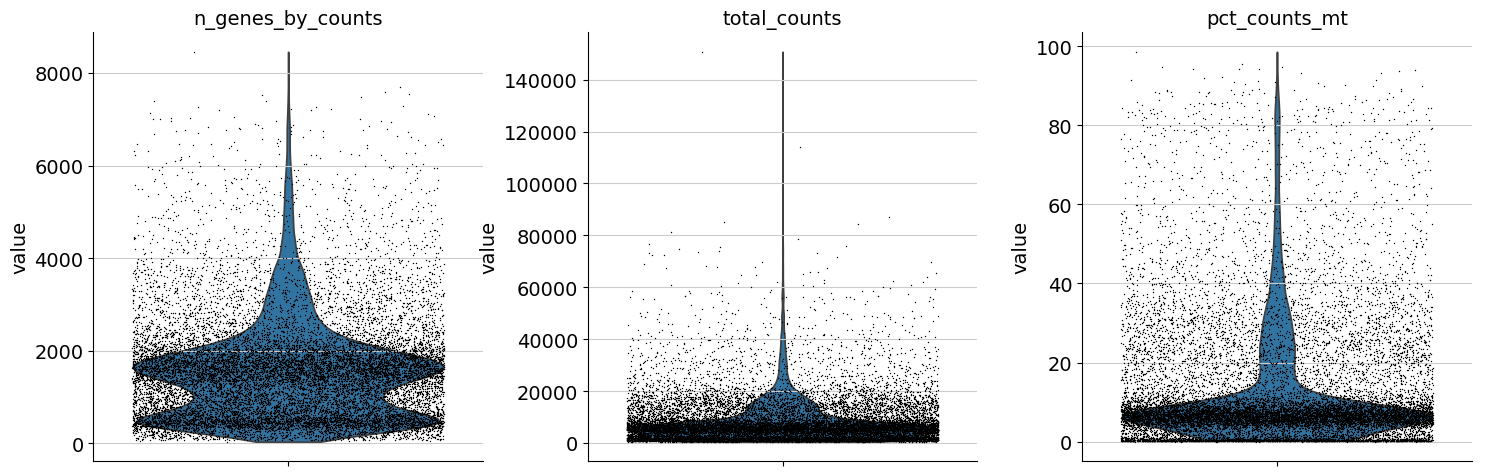

In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

Additionally, it is useful to consider QC metrics jointly by inspecting a scatter plot colored by `pct_counts_mt`.

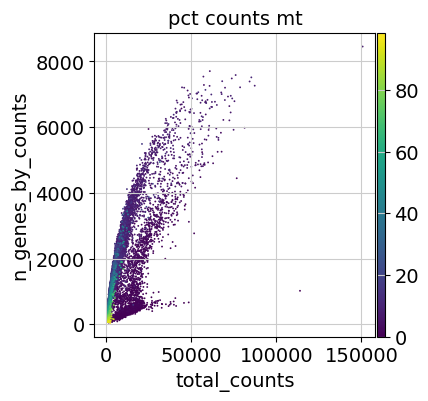

In [ ]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

Based on the QC metric plots, one could now remove cells that have too many mitochondrial genes expressed or too many total counts by setting manual or automatic thresholds. However, sometimes what appears to be poor QC metrics can be driven by real biology so we suggest starting with a very permissive filtering strategy and revisiting it at a later point. We therefore now only filter cells with less than 100 genes expressed and genes that are detected in less than 3 cells.

Additionally, it is important to note that for datasets with multiple batches, quality control should be performed for each sample individually as quality control thresholds can vary substantially between batches.

In [ ]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

### Doublet detection

As a next step, we run a doublet detection algorithm. Identifying doublets is crucial as they can lead to misclassifications or distortions in downstream analysis steps. Scanpy contains the doublet detection method Scrublet. Scrublet predicts cell doublets using a nearest-neighbor classifier of observed transcriptomes and simulated doublets. `scanpy.pp.scrublet` adds `doublet_score` and `predicted_doublet` to `.obs`. One can now either filter directly on `predicted_doublet` or use the `doublet_score` later during clustering to filter clusters with high doublet scores.

In [ ]:
sc.pp.scrublet(adata, batch_key="sample")

We can remove doublets by either filtering out the cells called as doublets, or waiting until we've done a clustering pass and filtering out any clusters with high doublet scores.

**See also:** Alternative methods for doublet detection within the scverse ecosystem are [DoubletDetection](https://github.com/JonathanShor/DoubletDetection) and [SOLO](https://docs.scvi-tools.org/en/stable/user_guide/models/solo.html). You can read more about these in the [Doublet Detection chapter](https://www.sc-best-practices.org/preprocessing_visualization/quality_control.html#doublet-detection) of Single Cell Best Practices.

## Normalization

The next preprocessing step is normalization. A common approach is count depth scaling with subsequent log plus one (log1p) transformation. Count depth scaling normalizes the data to a “size factor” such as the median count depth in the dataset, ten thousand (CP10k) or one million (CPM, counts per million). The size factor for count depth scaling can be controlled via `target_sum` in `pp.normalize_total`. We are applying median count depth normalization with log1p transformation (AKA log1PF).

In [ ]:
# Saving count data
adata.layers["counts"] = adata.X.copy()

In [ ]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

## Feature selection

As a next step, we want to reduce the dimensionality of the dataset and only include the most informative genes. This step is commonly known as feature selection. The scanpy function `pp.highly_variable_genes` annotates highly variable genes by reproducing the implementations of Seurat, Cell Ranger, and Seurat v3 depending on the chosen `flavor`.

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")

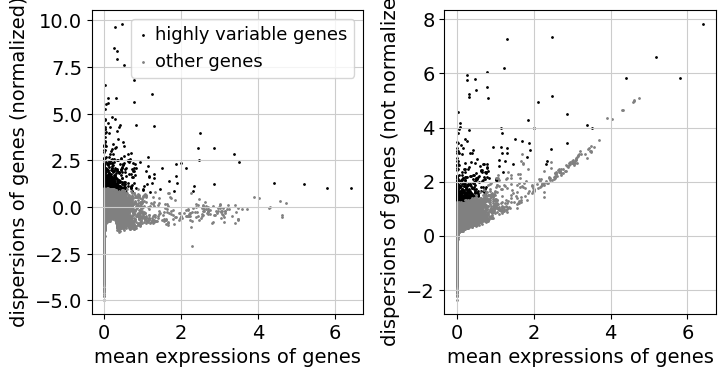

In [ ]:
sc.pl.highly_variable_genes(adata)

## Dimensionality Reduction
Reduce the dimensionality of the data by running principal component analysis (PCA), which reveals the main axes of variation and denoises the data.

In [ ]:
sc.tl.pca(adata)

Let us inspect the contribution of single PCs to the total variance in the data. This gives us information about how many PCs we should consider in order to compute the neighborhood relations of cells, e.g. used in the clustering function `scanpy.tl.leiden` or `scanpy.tl.tsne`. In our experience, there does not seem to be signifigant downside to overestimating the numer of principal components.

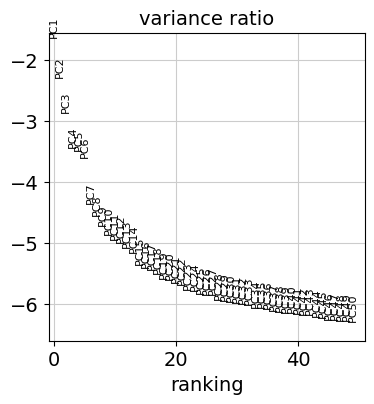

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

You can also plot the principal components to see if there are any potentially undesired features (e.g. batch, QC metrics) driving signifigant variation in this dataset. In this case, there isn't anything too alarming, but it's a good idea to explore this.

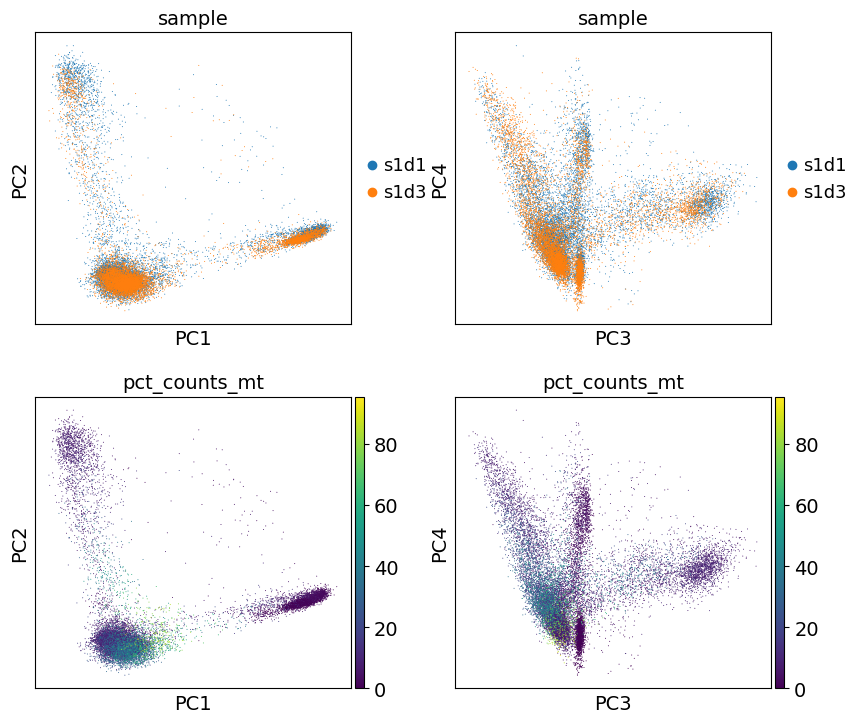

In [ ]:
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

## Nearest neighbor graph construction and visualization

Let us compute the neighborhood graph of cells using the PCA representation of the data matrix.

In [ ]:
sc.pp.neighbors(adata)

This graph can then be embedded in two dimensions for visualiztion with UMAP:

In [ ]:
sc.tl.umap(adata)

We can now visualize the UMAP according to the `sample`.

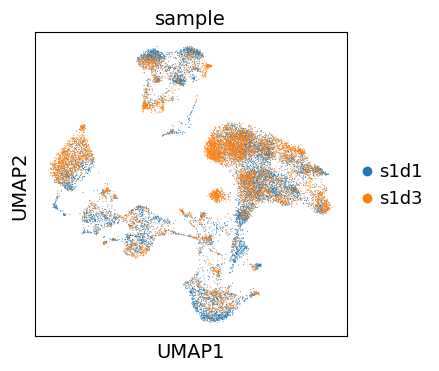

In [ ]:
sc.pl.umap(
    adata,
    color="sample",
    # Setting a smaller point size to get prevent overlap
    size=2,
)

Even though the data considered in this tutorial includes two different samples, we only observe a minor batch effect and we can continue with clustering and annotation of our data.

If you inspect batch effects in your UMAP it can be beneficial to integrate across samples and perform batch correction/integration. We recommend checking out [`scanorama`](https://github.com/brianhie/scanorama) and [`scvi-tools`](https://scvi-tools.org) for batch integration.

## Clustering

As with Seurat and many other frameworks, we recommend the Leiden graph-clustering method (community detection based on optimizing modularity). Note that Leiden clustering directly clusters the neighborhood graph of cells, which we already computed in the previous section.

In [ ]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster,
# especially for larger datasets
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

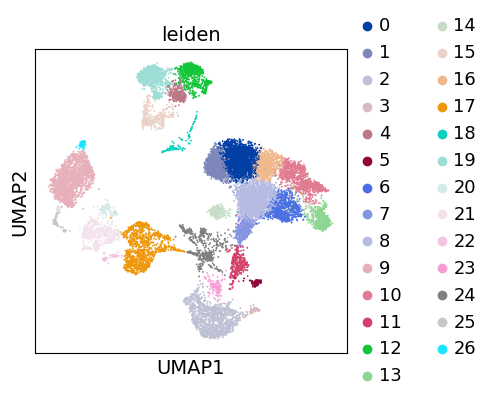

In [ ]:
sc.pl.umap(adata, color=["leiden"])

**How do I save a plot?** You can save a plot by accessing the returned Matplotlib figure, e.g. `sc.pl.umap(adata, color=['leiden'], show=False).figure.savefig('output_path.png')`

## Re-assess quality control and cell filtering

As indicated before, we will now re-assess our filtering strategy by visualizing different QC metrics using UMAP.

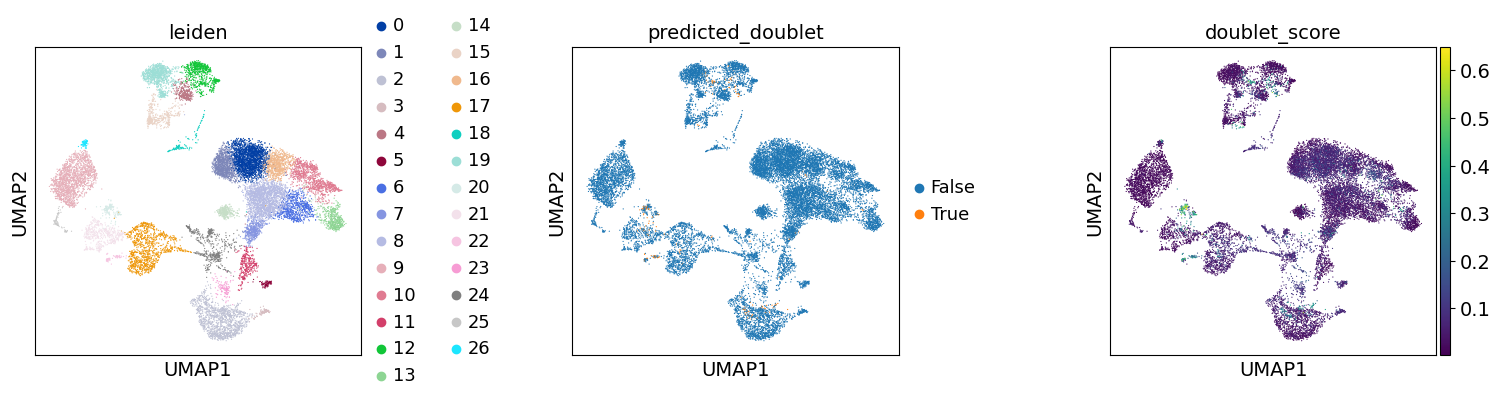

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)

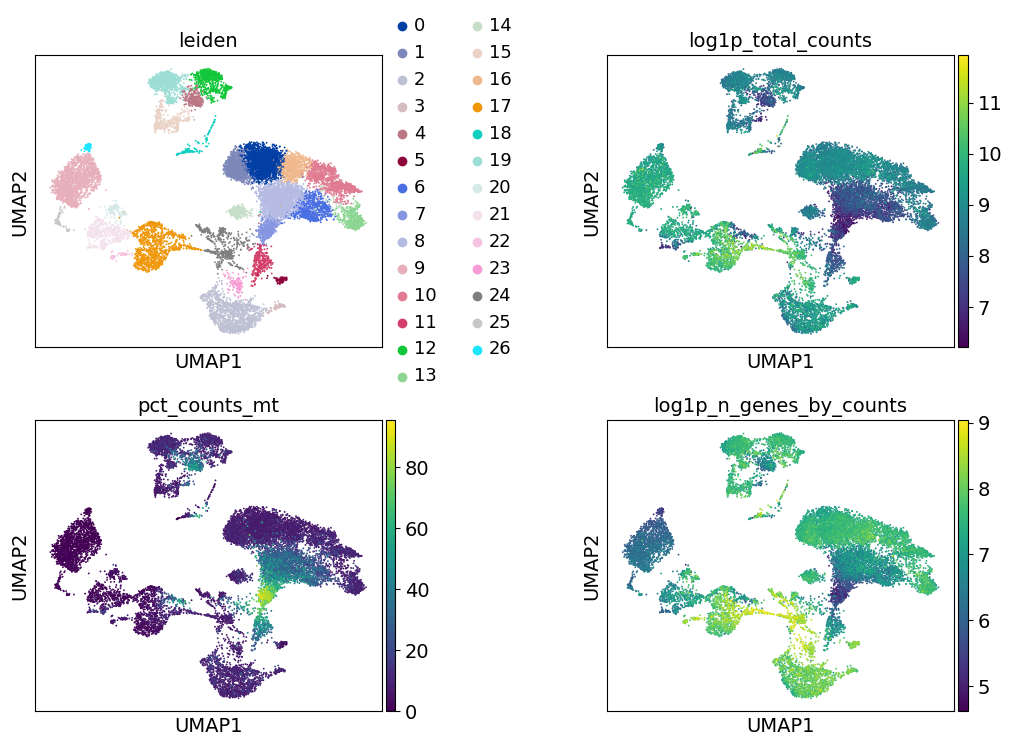

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

## Manual cell-type annotation

**Note:** This section of the tutorial is expanded upon using prior knowledge resources like automated assignment and gene enrichment in the scverse tutorial [here](https://scverse-tutorials.readthedocs.io/page/notebooks/basic-scrna-tutorial.html#cell-type-annotation)

Cell type annotation is laborous and repetitive task, one which typically requires multiple rounds of subclustering and re-annotation. It's difficult to show the entirety of the process in this tutorial, but we aim to show how the tools scanpy provides assist in this process.

We have now reached a point where we have obtained a set of cells with decent quality, and we can proceed to their annotation to known cell types. Typically, this is done using genes that are exclusively expressed by a given cell type, or in other words these genes are the marker genes of the cell types, and are thus used to distinguish the heterogeneous groups of cells in our data. Previous efforts have collected and curated various marker genes into available resources, such as [CellMarker](http://bio-bigdata.hrbmu.edu.cn/CellMarker/), [TF-Marker](http://bio.liclab.net/TF-Marker/), and [PanglaoDB](https://panglaodb.se/). The [cellxgene gene expression tool](https://cellxgene.cziscience.com/gene-expression) can also be quite useful to see which cell types a gene has been expressed in across many existing datasets.

Commonly and classically, cell type annotation uses those marker genes subsequent to the grouping of the cells into clusters. So, let's generate a set of clustering solutions which we can then use to annotate our cell types. Here, we will use the Leiden clustering algorithm which will extract cell communities from our nearest neighbours graph.

In [ ]:
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(
        adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

Notably, the number of clusters that we define is largely arbitrary, and so is the `resolution` parameter that we use to control for it. As such, the number of clusters is ultimately bound to the stable and biologically-meaningful groups that we can ultimately distringuish, typically done by experts in the corresponding field or by using expert-curated prior knowledge in the form of markers.

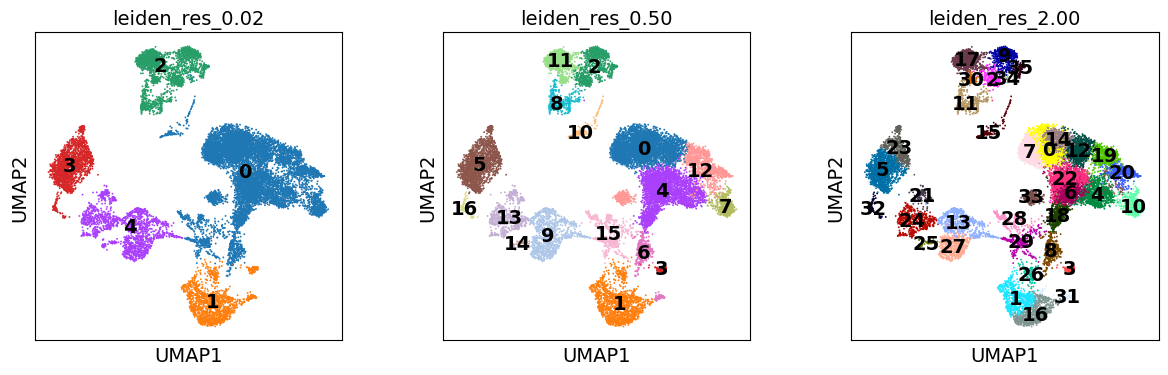

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

Though UMAPs should not be over-interpreted, here we can already see that in the highest resolution our data is over-clustered, while the lowest resolution is likely grouping cells which belong to distinct cell identities.

### Marker gene set

Let's define a set of marker genes for the main cell types that we expect to see in this dataset. These were adapted from [Single Cell Best Practices annotation chapter](https://www.sc-best-practices.org/cellular_structure/annotation.html), for a more detailed overview and best practices in cell type annotation, we refer the user to it.

In [ ]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

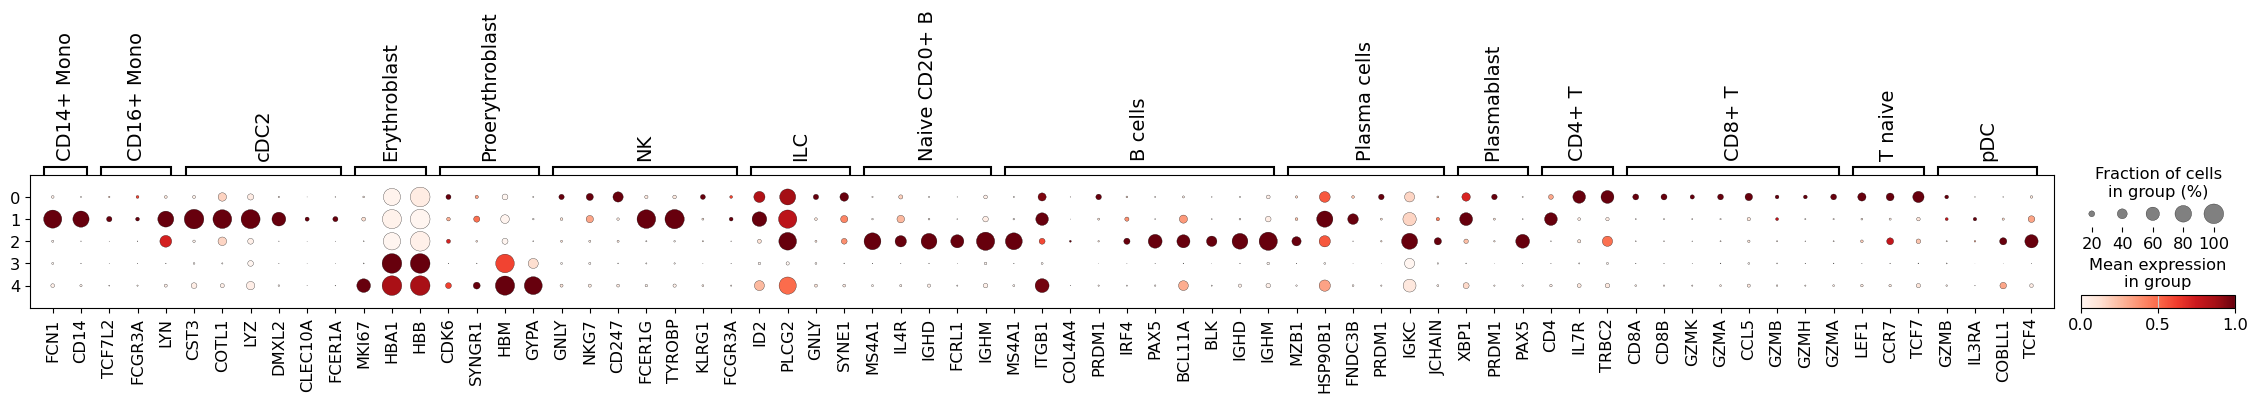

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")

There are fairly clear patterns of expression for our markers show here, which we can use to label our coarsest clustering with broad lineages.

In [ ]:
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map({
    "0": "Lymphocytes",
    "1": "Monocytes",
    "2": "B Cells",
    "3": "Erythroid",
    "4": "Erythroid",
})

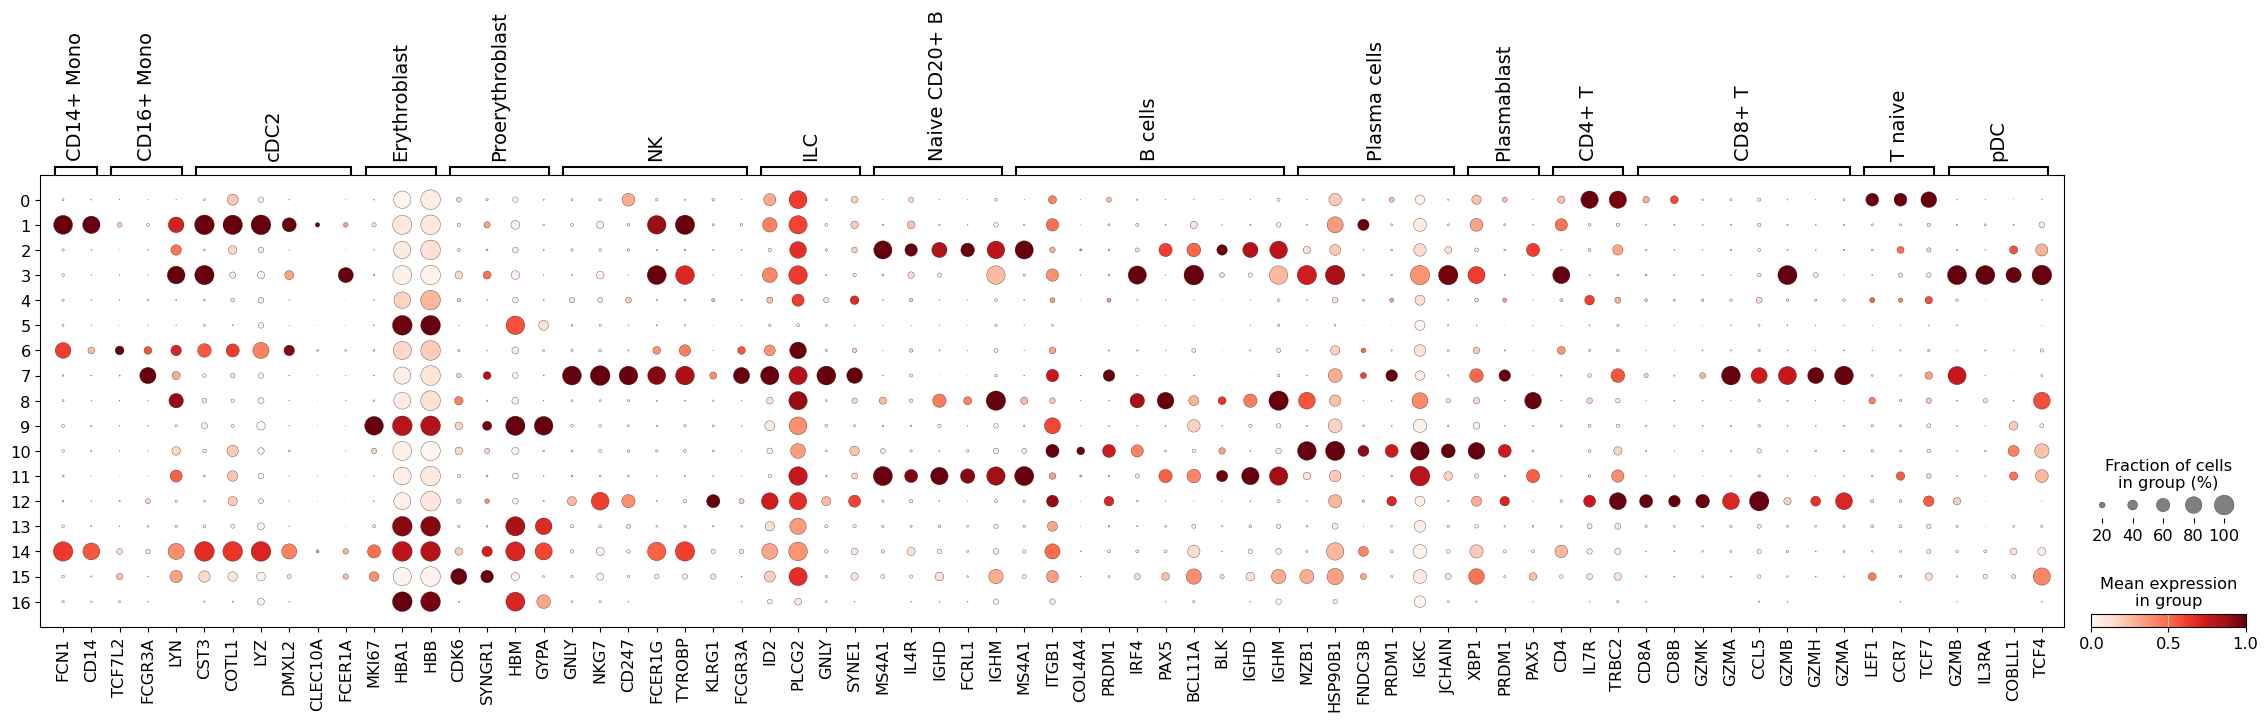

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.50", standard_scale="var")

This seems like a resolution that suitable to distinguish most of the different cell types in our data. As such, let's try to annotate those by manually using the dotplot above, together with the UMAP of our clusters. Ideally, one would also look specifically into each cluster, and attempt to subcluster those if required.

### Differentially-expressed Genes as Markers

Furthermore, one can also calculate marker genes per cluster and then look up whether we can link those marker genes to any known biology, such as cell types and/or states. This is typically done using simple statistical tests, such as Wilcoxon and t-test, for each cluster vs the rest.

In [ ]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")

We can then visualize the top 5 differentially-expressed genes on a dotplot.

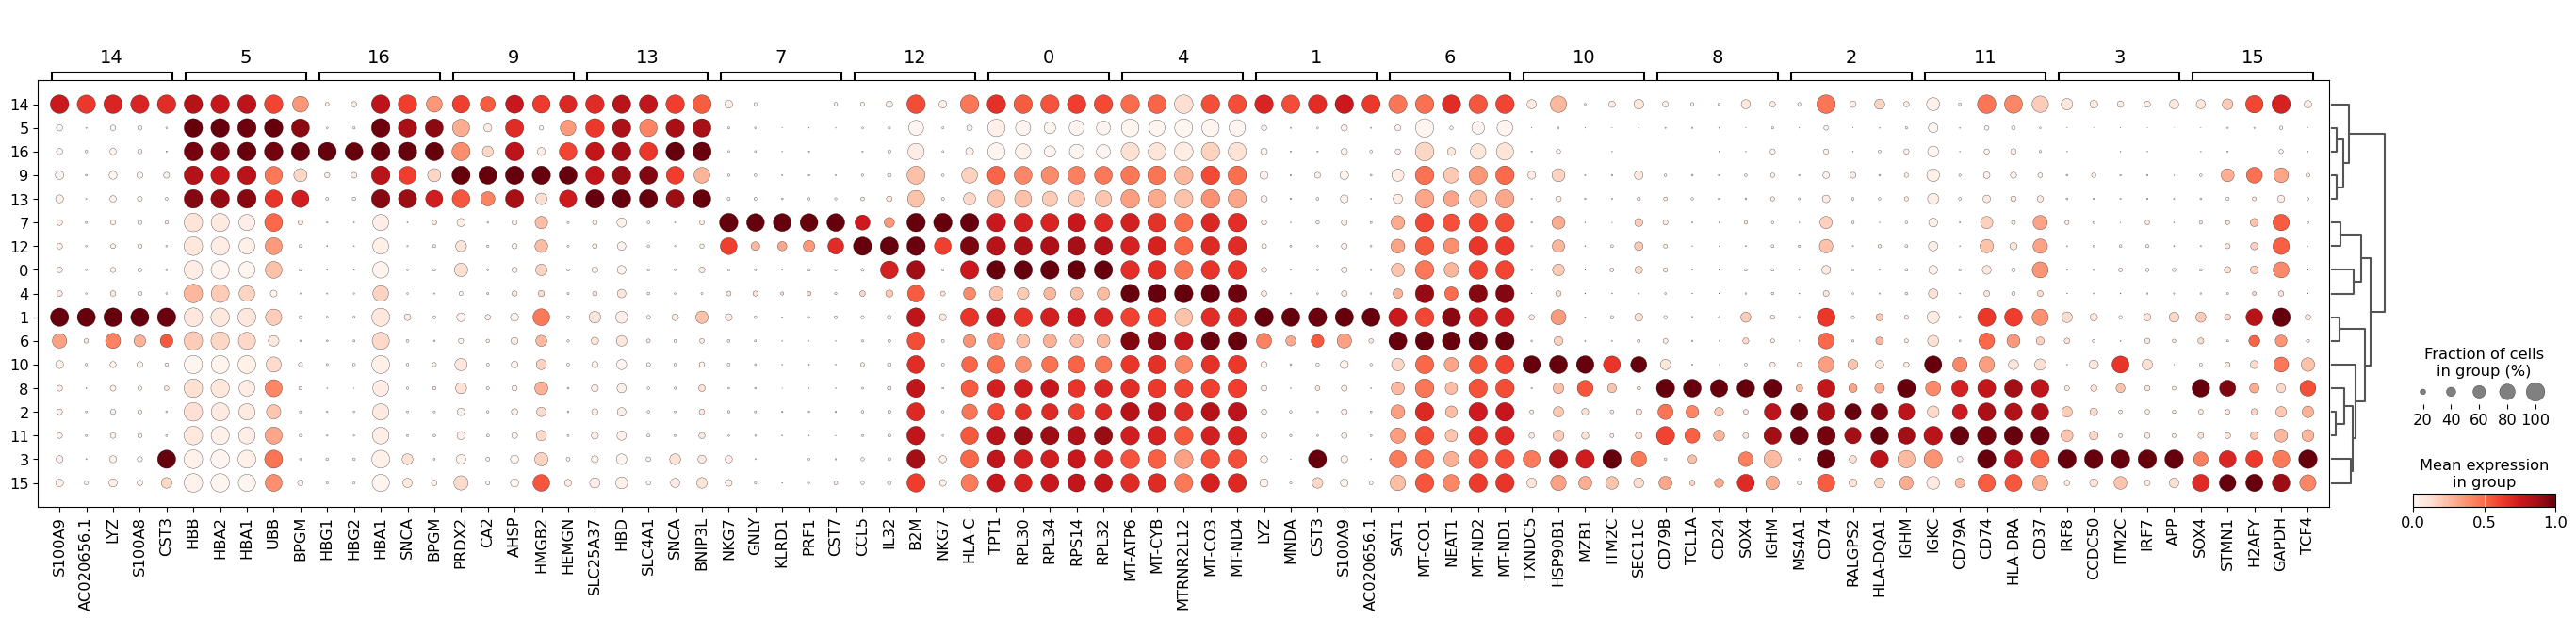

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5
)

We can then use these genes to figure out what cell types we're looking at. For example, Cluster 7 is expressing [*NKG7*](https://www.genecards.org/cgi-bin/carddisp.pl?gene=NKG7&keywords=nkg7) and [*GNLY*](https://www.genecards.org/cgi-bin/carddisp.pl?gene=GNLY&keywords=GNLY), suggesting these are [NK cells](https://en.wikipedia.org/wiki/Natural_killer_cell).

To create your own plots, or use a more automated approach, the differentially expressed genes can be extracted in a convenient format with `scanpy.get.rank_genes_groups_df`

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.610233,6.547157,9.728576e-278,2.279114e-273
1,GNLY,33.932396,7.375255,2.218155e-252,2.598235e-248
2,KLRD1,33.903980,5.843249,5.819822e-252,4.544699e-248
3,PRF1,33.111046,5.437215,2.060918e-240,1.207028e-236
4,CST7,32.995819,5.224056,9.324716e-239,4.369003e-235


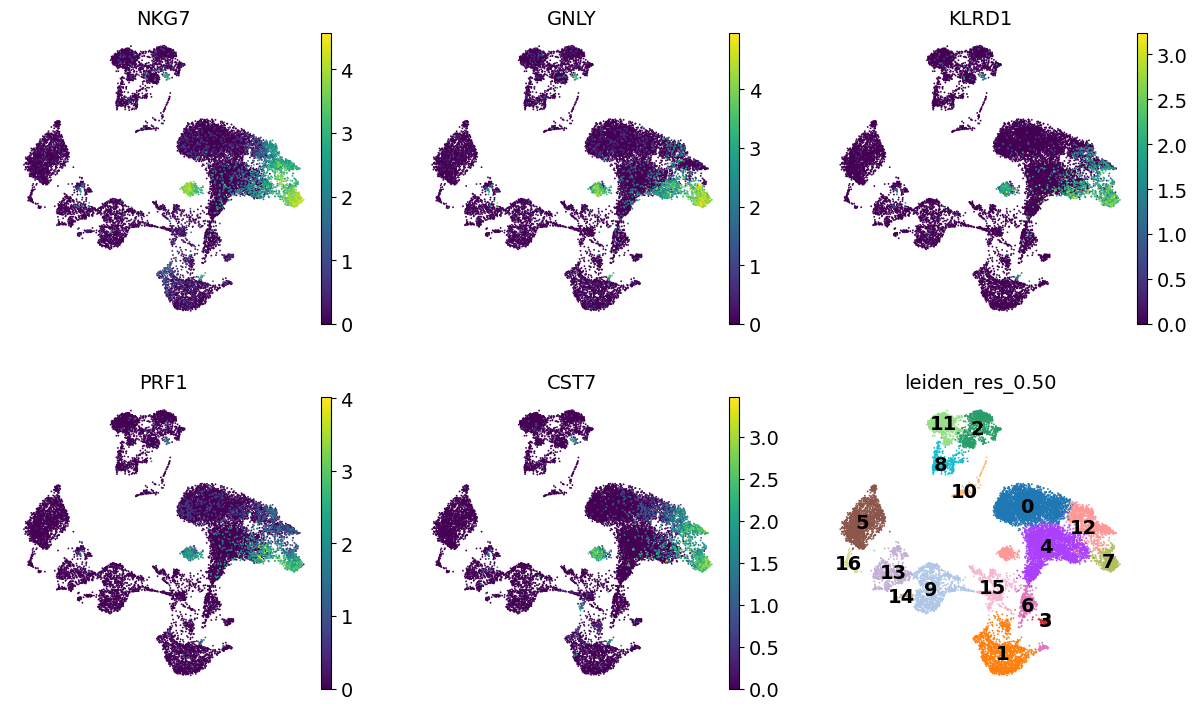

In [ ]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

You may have noticed that the p-values found here are extremely low. This is due to the statistical test being performed considering each cell as an independent sample. For a more conservative approach you may want to consider "pseudo-bulking" your data by sample (*e.g.* `sc.get.aggregate(adata, by=["sample", "cell_type"], func="sum", layer="counts")`) and using a more powerful differential expression tool, like `pydeseq2`.

---
# Module 11: Classifying cells from gene expression

**Workflow.** The cells are split into 60% training, 20% validation and 20% test (stratified). Five-fold cross-validation with grid search inside the training set picks the hyperparameters for each classifier family. The winning classifier is chosen by validation average precision and then evaluated once on the test set, with no further tuning.

### Cell 1: Import tools and define settings
Imports the classifiers and evaluation tools. 500 predictor genes are selected inside each training fold to keep computation manageable.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

### Cell 2: Prepare expression data and split the cells
B Cells get label 1 and other annotated cells get label 0. Each cell is normalized to a fixed total and log-transformed, and stratified training/validation/test partitions are created. This builds a separate matrix and leaves `adata` unchanged.

In [ ]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1361,8863,0.133
1,Validation,3408,453,2955,0.133
2,Test,3409,454,2955,0.133


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


### Cell 3: Define pipelines and search grids
Each pipeline removes constant genes and selects genes associated with the training labels; logistic regression and SVM also scale those features. Feature selection and scaling are inside the pipeline, so each cross-validation fold fits them using only its own training cells. The tutorial's all-cell PCA and highly variable genes are not reused.

In [ ]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

### Cell 4: Run five-fold grid search and choose the classifier
Grid search picks the hyperparameters with the highest mean CV average precision for each family and refits them on the full training partition. The three models are then compared by validation average precision. *This cell may take several minutes (the SVM is the slowest).*

In [ ]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9986,0.0008,0.9986,0.9998,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9986,0.0010,0.9981,0.9997,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9981,0.0011,0.9973,0.9996,{'classifier__C': 0.1}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.


If validation average precision is exactly tied, this code keeps the original model order: logistic regression, random forest, then SVM. A tie after rounding does not necessarily mean the underlying values are identical.

### Cell 5: Compare validation ROC curves
Plots the best model from each classifier family on the validation set. The selection criterion is still validation average precision.

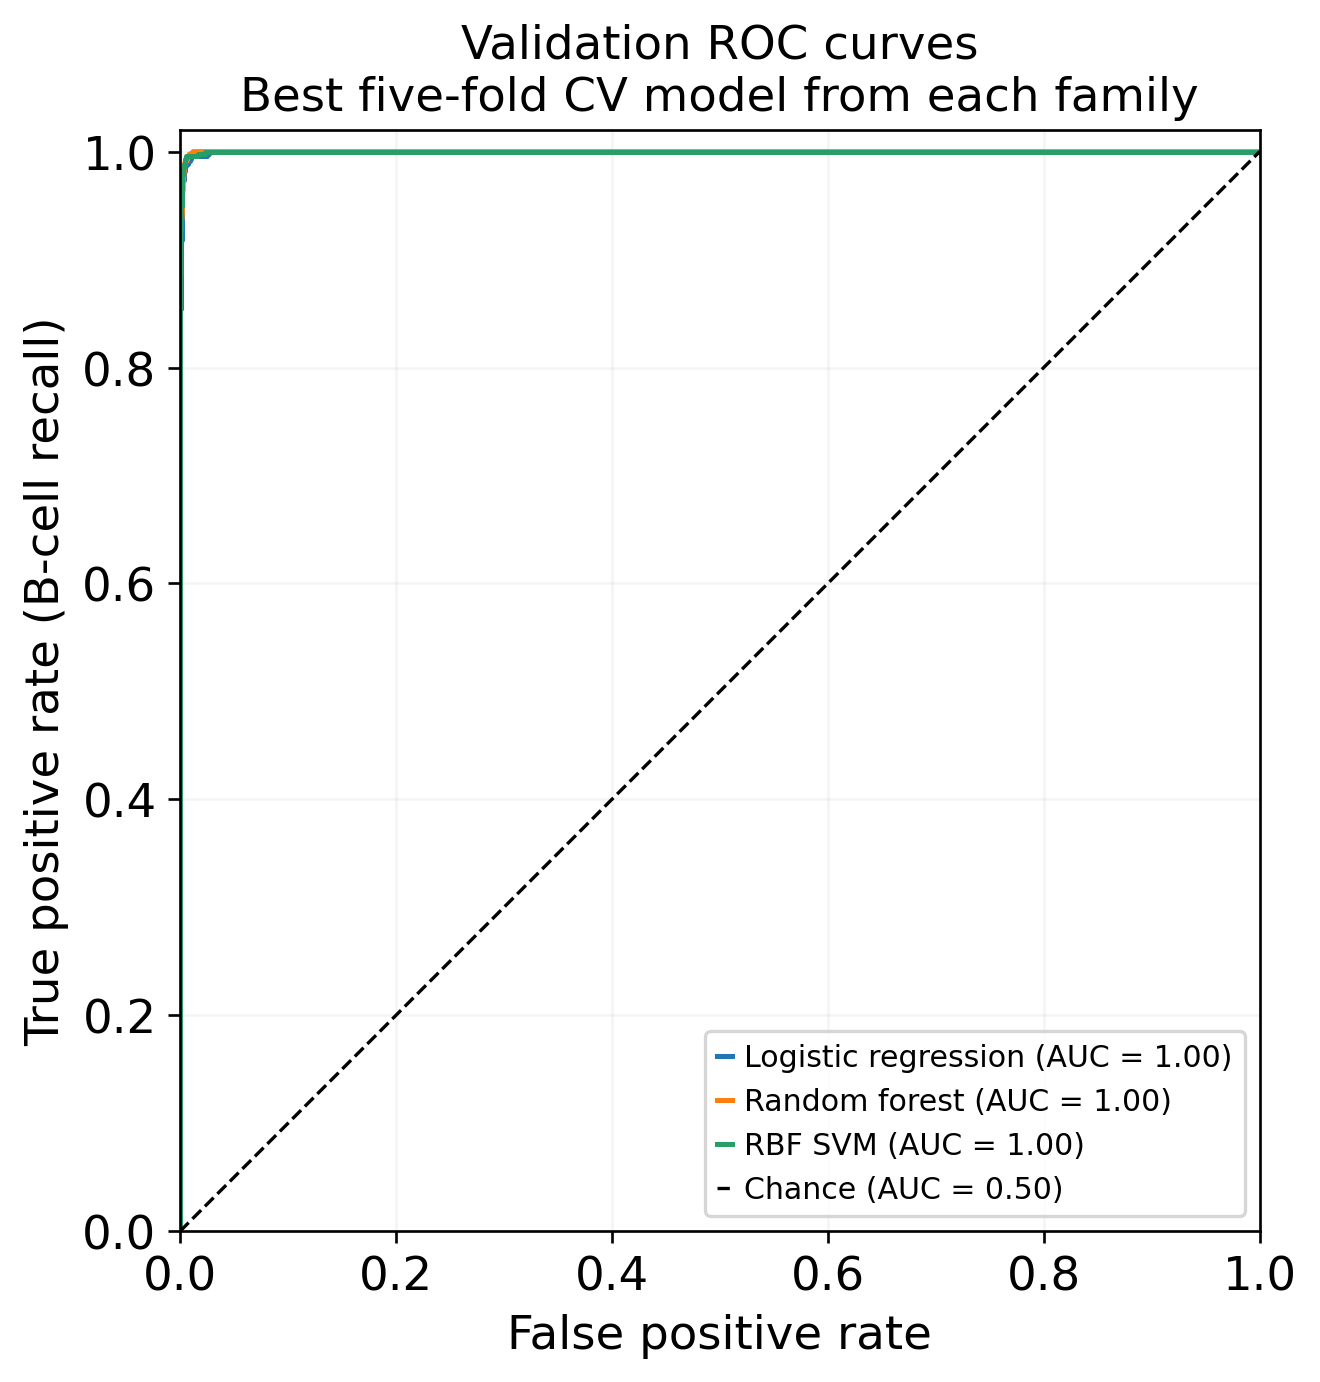

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

### Cell 6: Evaluate the winner on the test set
Evaluates the selected model with no further tuning or refitting, using the model's default classification threshold for the confusion matrix.

Final test evaluation: RBF SVM
Test average precision: 0.9986
Test ROC-AUC:           0.9998
Test B-cell prevalence: 0.1332

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.999     0.995     0.997      2955
              B Cells      0.968     0.991     0.979       454

             accuracy                          0.994      3409
            macro avg      0.983     0.993     0.988      3409
         weighted avg      0.995     0.994     0.994      3409



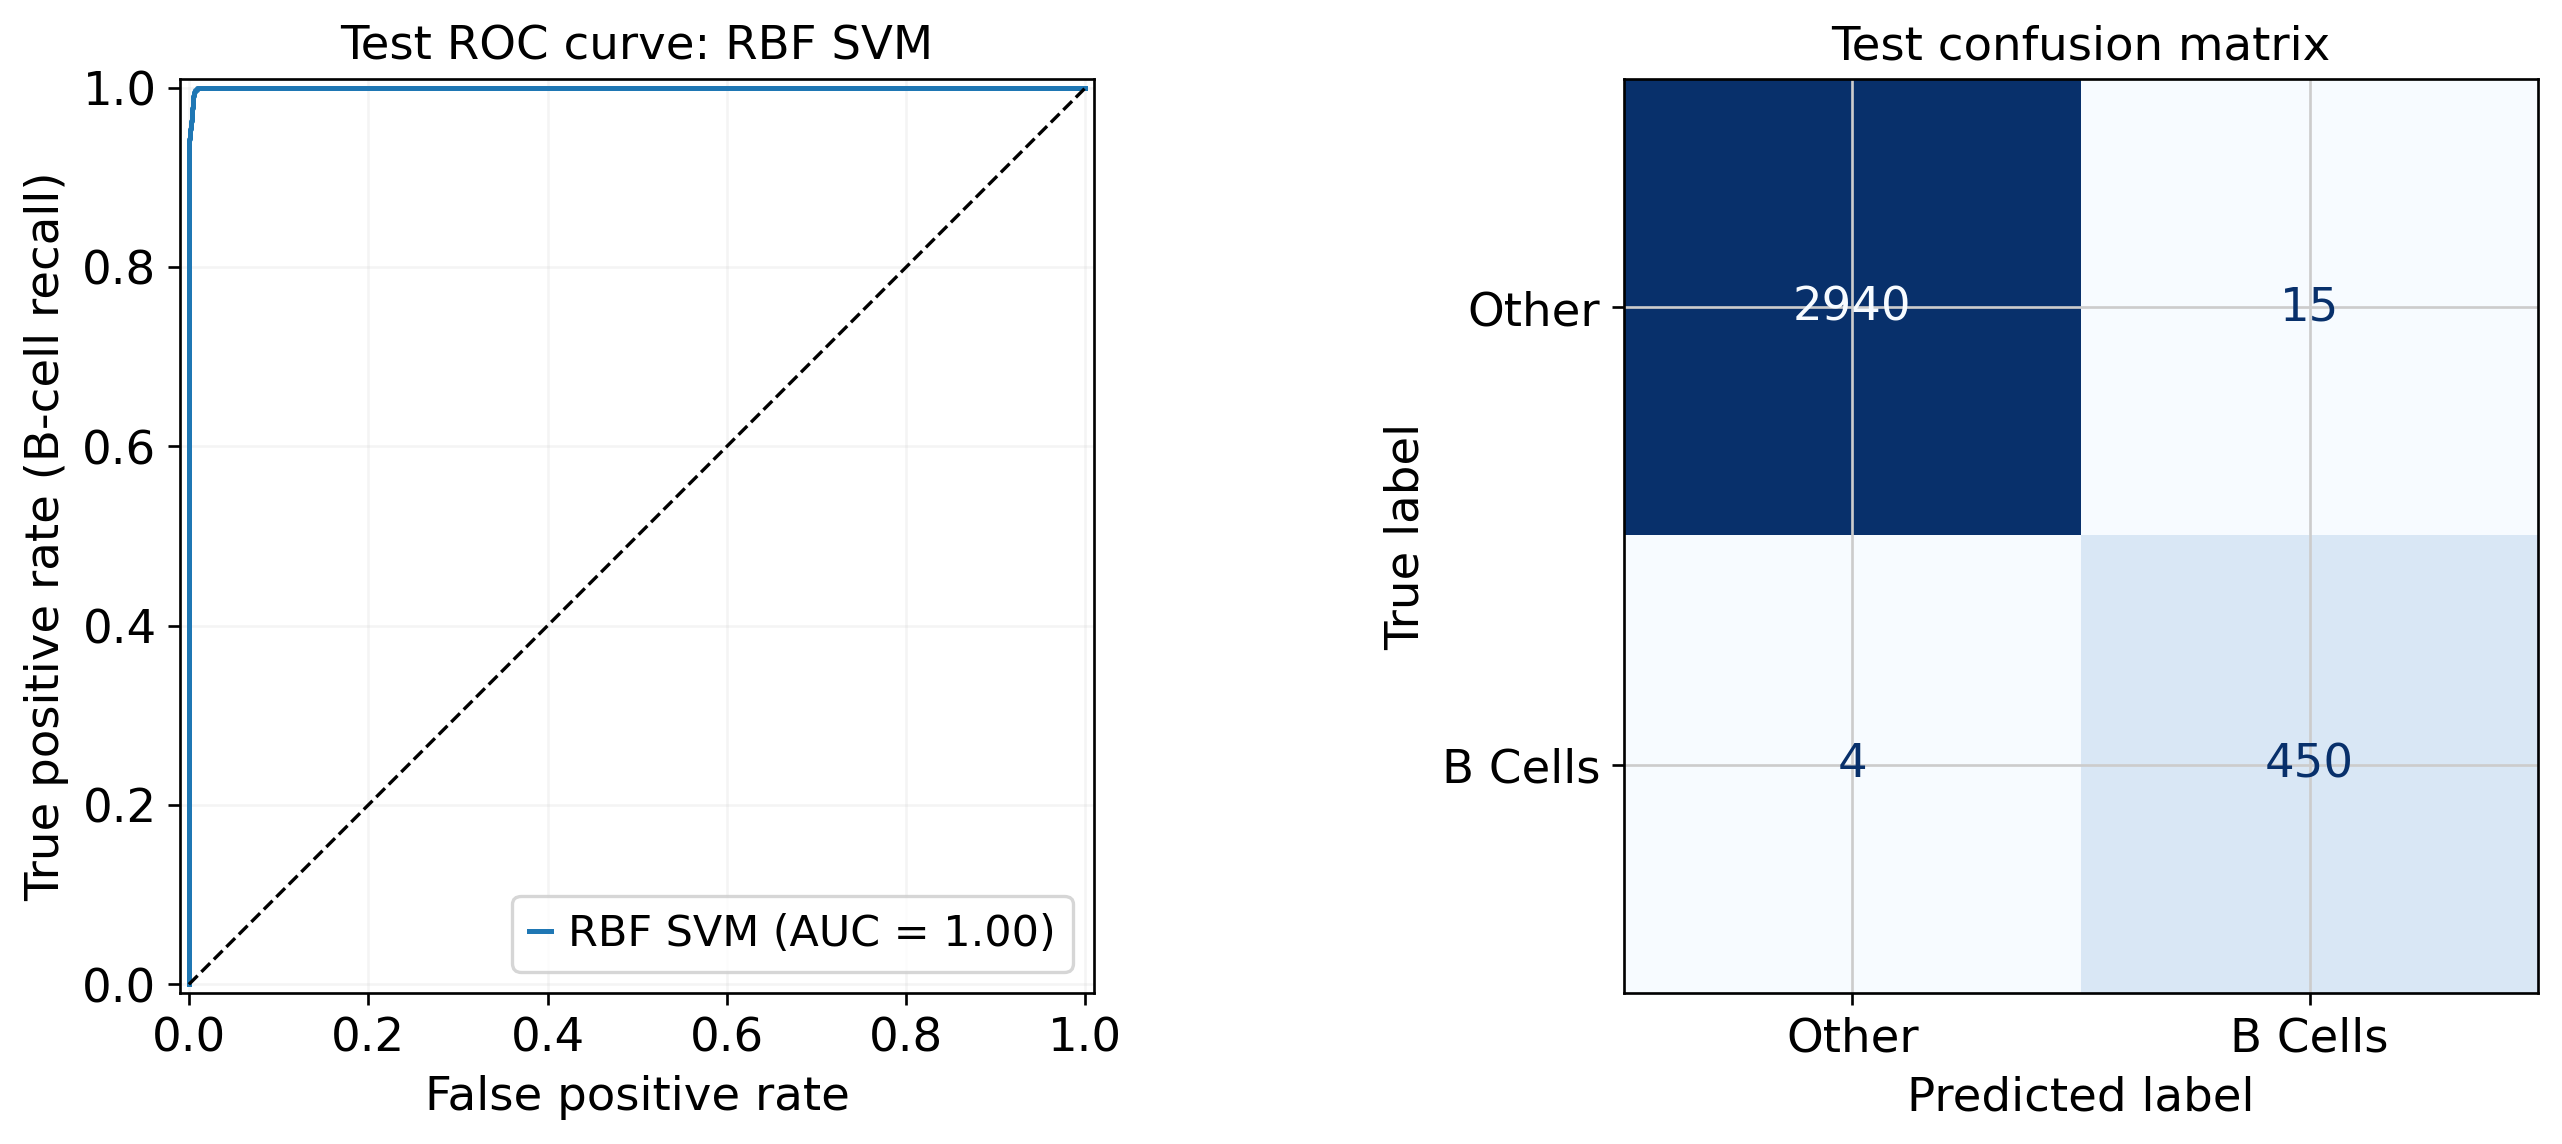

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,ATTCCTAAGTCTGGTT-1,0,0,-3.216881,True
1,CCCGGAAGTACTGGGA-1,0,0,-1.628788,True
2,GTCCTCAGTCTTGCGG-1,0,0,-3.238069,True
3,GCTGAATGTCTTTCTA-1,0,0,-3.185528,True
4,GGGTCACGTGCATGAG-1,0,0,-2.389968,True


In [ ]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?

**Your response:** The **observations** are individual **cells**: each row of the matrix is one bone-marrow mononuclear cell from samples s1d1 and s1d3 that passed the tutorial's QC filters and has a `cell_type_lvl1` annotation. That is **17,041 cells** (from 17,125 loaded: 8,785 from s1d1 and 8,340 from s1d3). The **predictor features** are the cells' **gene-expression values** for the **23,427 genes** kept after the tutorial's gene filter: the saved raw counts (`adata.layers["counts"]`), normalized per cell to 10,000 total counts and log1p-transformed. Inside each training fold, constant genes are removed and the **500 genes** most associated with the label (ANOVA F-test, `SelectKBest`) are kept. The **target label** is binary: **1 = "B Cells"** and **0 = every other annotated cell type** (Lymphocytes, Monocytes, Erythroid), taken from the tutorial's manual annotation of the Leiden clusters.

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

**Your response:** The training partition has **10,224 cells: 1,361 B Cells and 8,863 other cells**. A classifier that predicts "Other" for every cell is correct for all 8,863 other cells, so its **accuracy = 8,863 / 10,224 = 0.867 (86.7%)**. Its **B-cell recall would be 0**, because it never predicts a B cell (TP = 0, so TP / (TP + FN) = 0). High accuracy is possible here only because B cells are a minority class, which is why accuracy alone is a poor metric for this task and why we use average precision. We **stratify** the split so that the training, validation and test sets all keep the same B-cell proportion, as the summary table shows. Without stratification, a random split could put noticeably more or fewer B cells in one partition. That would make the validation and test metrics less comparable, and in the worst case leave a CV fold with too few positive cells to train or score.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?

**Your response:** The selected classifier was the **RBF SVM**, with best hyperparameters **C = 1.0** and **gamma = 0.001**. It came inside a pipeline that removes constant genes, selects 500 genes with `SelectKBest(f_classif)`, and scales them with `StandardScaler(with_mean=False)`. It was chosen because it had the **highest validation average precision (0.9986)**, ahead of the random forest (0.9981) and logistic regression (C = 0.1; 0.9973). Its five-fold CV average precision was 0.9986 (SD 0.0008), and its validation ROC-AUC was 0.9998. All three families performed almost identically (validation AP 0.997–0.999), so the SVM's win is very small and might change with a different random split. Any of the three would separate B cells well.

### 4. Interpret what the classifier learned
What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

**Your response:** The classifier learned to **reproduce the tutorial's "B Cells" annotation** from expression values. That annotation came from assigning a whole Leiden cluster (resolution 0.02) to "B Cells" based on marker genes in a dot plot. So the model learned to recognize the expression pattern that defines that cluster (for example B-cell genes such as *MS4A1*, *PAX5*, *BCL11A*, *BLK*), as a statistical shortcut for predicting the cluster label. This is **not the same as establishing a cell's true biological identity**. The labels themselves are computational and partly subjective: they depend on the QC, normalization, number of PCs, clustering resolution and the analyst's marker choices, and a coarse cluster can contain mislabeled cells, doublets or related types (such as plasma cells or pre-B cells). Establishing biological identity would require independent evidence, such as surface-protein measurements (CD19/CD20 by flow cytometry or CITE-seq), sorted or reference-labeled cells, or functional assays. High agreement only shows the model is consistent with the annotation, not that the annotation is correct.

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?

**Your response:** A **false positive** is a cell the classifier predicts as a B cell, but whose tutorial annotation is "other" (Lymphocyte, Monocyte or Erythroid). It might be a cell whose expression looks partly B-cell-like (a doublet, a plasma cell or B-cell progenitor annotated into another cluster, or a lymphocyte at the cluster boundary). It could also be a cell that was *mislabeled* by the coarse cluster annotation, so the classifier might actually be right. A **false negative** is a cell annotated as a B cell that the classifier calls "other". That could be a B cell with low capture/sequencing depth and weak marker expression, an atypical B-cell state, or a cell wrongly included in the B-cell cluster. In both cases the "error" is measured against the clustering-based label, which is itself not ground truth.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

**Your response:** **Yes, it is a very good classifier for this task**, as measured against the tutorial's labels. On the 3,409 held-out test cells (454 B Cells, prevalence 0.133), the confusion matrix at the default threshold is **TN = 2,940, FP = 15, FN = 4, TP = 450**:

| Metric | Calculation | Value |
|---|---|---|
| Sensitivity (B-cell recall) | TP / (TP + FN) = 450 / 454 | **0.991** |
| Precision | TP / (TP + FP) = 450 / 465 | **0.968** |
| Specificity | TN / (TN + FP) = 2,940 / 2,955 | **0.995** |
| F1 score | 2 × P × R / (P + R) | **0.979** |

It finds **99.1% of the B cells** (only 4 missed) and wrongly calls only 15 of 2,955 other cells B cells. When it predicts "B cell" it is right about 97% of the time. Test accuracy is 0.994, test average precision 0.9986 and ROC-AUC 0.9998, much better than the "always Other" baseline (accuracy 0.867, recall 0). The test results match the validation results, so the model did not overfit the training data. Most of the remaining errors are false positives, so if B-cell purity mattered more, the decision threshold could be raised slightly. The main caveat is in Q7: these numbers measure agreement with clustering-derived labels made from the same data, so they likely overstate how well the model would identify B cells in a new, independently labeled dataset.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

**Your response:** **No, the test set is not fully independent.** The classifier pipeline itself is leakage-safe: gene selection, scaling and grid search were fit on training cells only. But the **labels** were produced *before* the split, using **all cells, including the future test cells**. The highly variable genes, PCA, nearest-neighbor graph, Leiden clustering and the manual marker-based annotation were all computed on the full dataset. Each test cell therefore helped define the B-cell cluster: it shaped the PCA axes, it was a neighbor in the graph, and its cluster label was decided from expression patterns that the classifier later uses as features. The label is essentially a function of the same expression data the model sees, so the task is partly circular: the classifier is asked to recover clusters that were drawn on that very expression space, with the test cells included. **High test accuracy therefore mostly shows that the cluster boundaries are easy to reproduce from expression**, not that the model would correctly identify B cells in a new experiment. Also, cells from the same donor/sample appear in both training and test sets, so donor and batch effects are shared. A **stronger evaluation** would need labels and data that are independent of the training analysis:
- Re-run the clustering/annotation using training cells only, then project test cells (e.g., with `sc.tl.ingest`).
- Better, test on a **held-out donor, sample or batch** (e.g., train on s1d1, test on s1d3, or use another site from the NeurIPS dataset).
- Ideally, use **independent ground-truth labels**, such as CITE-seq surface-protein markers (CD19/CD20), FACS-sorted populations or expert-curated reference annotations, rather than labels derived from the same clustering.